# Introduction
In this report we will try to find the best machine learning model to predict student performance. We predict their `score` based on various characteristics of the students. To do this, we first load the required R packages, followed by loading the data. We then describe and pre-process the data. Next, we train various different models and compare them using cross-validation. Lastly we choose the best model using the performance metric Mean Squared Error (MSE).

In [1]:
# Packages used in this notebook. Install them once with:
# install.packages(c("tidyverse", "rpart", "rpart.plot", "randomForest", "FNN", "xgboost"))
library(tidyverse)
library(rpart)
library(rpart.plot)
library(randomForest)
library(FNN)
library(xgboost)


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


randomForest 4.7-1.2



Type rfNews() to see new features/changes/bug fixes.




Attaching package: ‘randomForest’




The following object is masked from ‘package:dplyr’:

    combine




The following object is masked from ‘package:ggplot2’:

    margin




In [2]:
# Load data
train <- readRDS("data/train.rds")
test <- readRDS("data/test.rds")


# Data description

The data describe 316 secondary school students from two Portuguese schools. Each student is characterized by 30 predictors: 17 categorical variables (such as school, sex, parents' jobs and whether the student wants to pursue higher education) and 13 numeric variables, most of which are ordinal scales such as parental education, weekly study time and alcohol consumption. The test data contain 79 students for whom the score has to be predicted.

The outcome score is a normalized exam grade with a mean of about 0 and values ranging from -2.71 to 2.23. In this report we test which features most influence the performance outcome, and we predict the score based on these features.

Figure 1 shows the distribution of the performance scores. The figure shows a bell curve, with most students scoring between -1 and 1. Very few students score -2 or lower, or 2 or higher. Figure 2 shows the score per number of past class failures. As shown in the figure, students with more past class failures score lower on average, although the spread within each group is large. We chose this visualization because the number of past failures stands out as one of the clearest patterns in the data.


[1] "Train dimensions:"


[1] 316  31


[1] "Test dimensions:"


[1] 79 30


[1] "Train structure:"


...

    school        sex        age    address    famsize    Pstatus       Medu 
         0          0          0          0          0          0          0 
      Fedu       Mjob       Fjob     reason   guardian traveltime  studytime 
         0          0          0          0          0          0          0 
  failures  schoolsup     famsup       paid activities    nursery     higher 
         0          0          0          0          0          0          0 
  internet   romantic     famrel   freetime      goout       Dalc       Walc 
         0          0          0          0          0          0          0 
    health   absences      score 
         0          0          0 


[1] "Missing values in test:"


    school        sex        age    address    famsize    Pstatus       Medu 
         0          0          0          0          0          0          0 
      Fedu       Mjob       Fjob     reason   guardian traveltime  studytime 
         0          0          0          0          0          0          0 
  failures  schoolsup     famsup       paid activities    nursery     higher 
         0          0          0          0          0          0          0 
  internet   romantic     famrel   freetime      goout       Dalc       Walc 
         0          0          0          0          0          0          0 
    health   absences 
         0          0 


[1] "Summary of score:"


    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-2.70532 -0.63494 -0.02769 -0.01620  0.64029  2.23458 


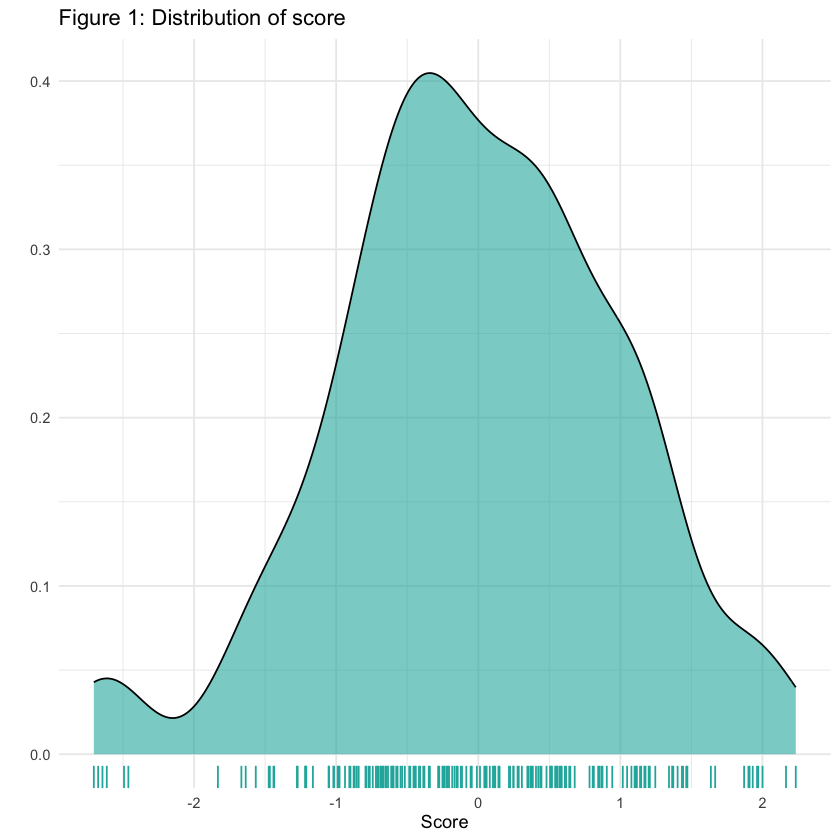

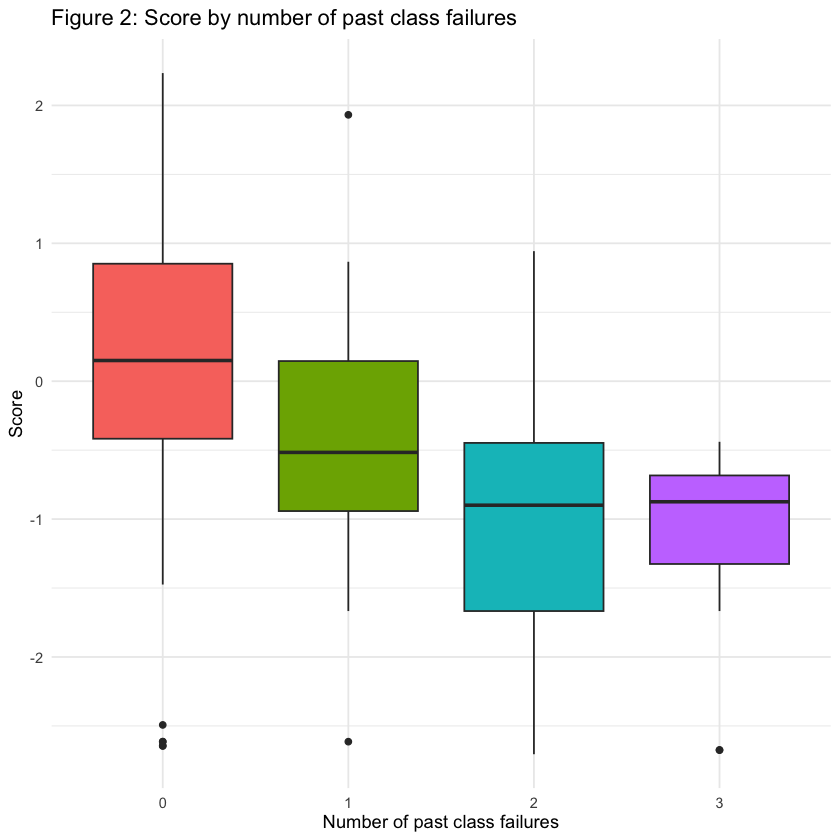

In [3]:
#| label: eda-visualization

print("Train dimensions:")
print(dim(train))
print("Test dimensions:")
print(dim(test))

# Structure of the data
print("Train structure:")
str(train)

# Missing values in all columns
print("Missing values in train:")
print(colSums(is.na(train)))
print("Missing values in test:")
print(colSums(is.na(test)))

# Summary of the outcome
print("Summary of score:")
print(summary(train$score))

# Figure 1: what does the outcome look like
ggplot(train, aes(x = score)) +
  geom_density(fill = "light seagreen", alpha = 0.6) +
  geom_rug(colour = "light seagreen") +
  labs(title = "Figure 1: Distribution of score", x = "Score", y = "") +
  theme_minimal()

# Figure 2: which student characteristic is most clearly related to the score
ggplot(train, aes(x = factor(failures), y = score, fill = factor(failures))) +
  geom_boxplot() +
  labs(title = "Figure 2: Score by number of past class failures",
       x = "Number of past class failures", y = "Score") +
  theme_minimal() +
  theme(legend.position = "none")

# Data transformation and pre-processing

All variables were already stored with the correct type (factors for the categorical variables, numeric for the others) and no values were missing, so no type conversion or imputation was necessary. We treated the ordinal variables, such as parental education, weekly study time and alcohol consumption, as numeric rather than as categories, because their order is meaningful and treating them as unordered categories would considerably increase the number of predictors relative to our sample size of 316 students.

The only transformation we applied is to the number of absences, which is strongly right-skewed: most students miss few classes, while a small number miss a great many. We therefore replaced it by log(absences + 1), which reduces the influence of these few extreme students; the constant 1 is added because log(0) is undefined. This transformation is applied to each student separately and does not use information from other students, so no information leaks between the training and validation data. The models require different input formats: linear regression, the decision tree and the random forest can use the data frame directly, whereas KNN and XGBoost require a numeric matrix. For these two models we converted every categorical variable into 0/1 dummy variables with `model.matrix()`. KNN additionally needs standardised predictors, because it is based on distances; the means and standard deviations for this are computed on the training data only.

In [4]:
# Create copies of the data for data transformations
clean_train <- train
clean_test <- test

# Reduce the impact of a few students with unusually high absences
clean_train$absences <- log(clean_train$absences + 1)
clean_test$absences <- log(clean_test$absences + 1)

# Model description

We compare five models that differ in how flexible they are. Linear regression assumes a straight-line effect of every predictor, KNN predicts a student from the most similar students in the data, a single regression tree splits the data into groups and the random forest and XGBoost combine many decision trees.

We also include a trivial baseline that ignores all predictors and always predicts the mean score of the training data. Because the outcome is standardized, this baseline has an MSE of about 1. Any model that does not clearly beat it has learned nothing useful from the student characteristics, so it gives us a reference point for judging whether the other models are worth anything at all.

The following sections describe each model, what it assumes, and what its strengths and weaknesses are. The models are compared in the next section.

## Linear regression

Linear regression predicts the outcome as a weighted sum of the predictors. It finds the weights by minimising the sum of squared residuals, so the fitted line is the one that is as close as possible to all observations at once. Categorical variables such as the mother's job are represented by dummy variables, so each category gets its own weight.

Linear regression is the simplest model we use here and it has no tuning parameters, which makes it a natural reference point; If the more flexible models do not beat it, the relationships in the data are probably close to linear. It is also easy to interpret, since each coefficient directly shows how much the score changes when a predictor increases by one unit.

On the other hand, linear regression assumes that every predictor has a straight-line effect and that these effects simply add up. It cannot capture interactions between predictors or non-linear patterns unless we add them by hand. With 316 students and almost 40 dummy and numeric predictors, it also runs some risk of overfitting, since every predictor gets its own coefficient regardless of whether it is useful.


In [5]:
lm_model <- lm(score ~ ., data = clean_train)

# Model summary
summary(lm_model)


Call:
lm(formula = score ~ ., data = clean_train)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.62952 -0.52479  0.04025  0.55464  1.82600 

Coefficients:
                   Estimate Std. Error t value Pr(>|t|)    
(Intercept)       1.5721152  0.9369096   1.678  0.09448 .  
schoolMS          0.0980065  0.1782251   0.550  0.58283    
sexM              0.3697558  0.1164562   3.175  0.00167 ** 
age              -0.1032977  0.0505226  -2.045  0.04184 *  
addressR         -0.0885359  0.1383152  -0.640  0.52264    
famsizeLE3        0.1253348  0.1125660   1.113  0.26649    
PstatusT         -0.0509367  0.1695449  -0.300  0.76407    
Medu              0.0679707  0.0737598   0.922  0.35759    
Fedu              0.0421668  0.0644928   0.654  0.51377    
Mjobhealth        0.2175944  0.2588886   0.840  0.40136    
Mjobother        -0.2183125  0.1649078  -1.324  0.18665    
Mjobservices     -0.0254821  0.1838298  -0.139  0.88985    
Mjobteacher      -0.3480869  0.2494625  -1.395  0.

## KNN

KNN predicts the score of a student from the k most similar students in the training data. It measures similarity by Euclidean distance, finds the k nearest students, and takes the average of their scores as the prediction. Because the prediction depends entirely on distances, the categorical variables have to be converted into dummy variables and all predictors have to be standardised.

KNN is heavily reliant on the k value, so in our code here (and later in the cross-validation) we tested out different k values to find the optimal k for KNN.

KNN is a quick and easy model which utilizes lazy learning, meaning it has no training time. On the other hand, KNN suffers from the curse of dimensionality: it is sensitive to irrelevant features and noise. This is a real concern here, because after dummy coding we have almost 40 predictors for only 316 students.


In [6]:
# KNN needs a numeric matrix, so factors are one-hot encoded with model.matrix()
knn_x <- model.matrix(score ~ . - 1, data = clean_train)
knn_y <- clean_train$score
knn_test_x <- model.matrix(~ . - 1, data = clean_test)

# Train and test must have exactly the same columns in the same order
stopifnot(identical(colnames(knn_x), colnames(knn_test_x)))

## Regression tree and ensembles

Decision trees are used to predict both continuous values and categories using recursive partitioning. The trees are made by first finding a split in the dataset that makes observations as similar as possible on the outcome within that split. This process is then repeated within each resulting subset. Decision trees are both easy to use and handle missing values well. In this report we will use a regression tree model to predict the score of the students, as the score has continuous values. However, single decision trees tend to overfit the training data. Therefore, it is better to use them as basic building blocks for ensembles. Here, we use both random forests and boosting to avoid overfitting the data.

Random forests can be described as bagged trees that use feature sampling. The random forest algorithm creates many different decision trees using random parts of the data. The random forest model gives the average prediction over all the different decision trees. At each split only a random subset of the predictors is considered, which makes the individual trees less similar to each other and therefore improves the averaging. Random forests assume that each tree makes its own decisions, that random parts of the data are used, that enough data is used and that combining different predictions improve the accuracy of the model. Just like single decision trees, random forest models handle missing data well. Additionally, the risk of overfitting is reduced by combining multiple decision trees. However, random forests can be time consuming due to being computationally intensive with large numbers of trees.

Boosting can be described as an ensemble of weak learners. This algorithm makes multiple decision trees that are too simple. It then makes more of them for observations with big residuals and adds them up. This way, many weak models are combined into a strong model. For this assignment we use the go-to implementation of boosting: XGBoost. One advantage of XGBoost is that it provides parameters and regularization for fine tuning. Additionally, it is available for multiple programming languages. However, Just like random forest models, XGBoost is computationally intensive. Furthermore, XGBoost can still overfit on small datasets. Because boosting keeps correcting errors, it can overfit, especially on a small dataset like ours. XGBoost limits this with shallow trees (`max_depth`), a minimum number of students per leaf (`min_child_weight`), random subsampling of students and predictors for each tree (`subsample`, `colsample_bytree`), a penalty on tree complexity, and the number of trees (`nrounds`). These settings must be tuned, which we did with cross-validation (see Model comparison).

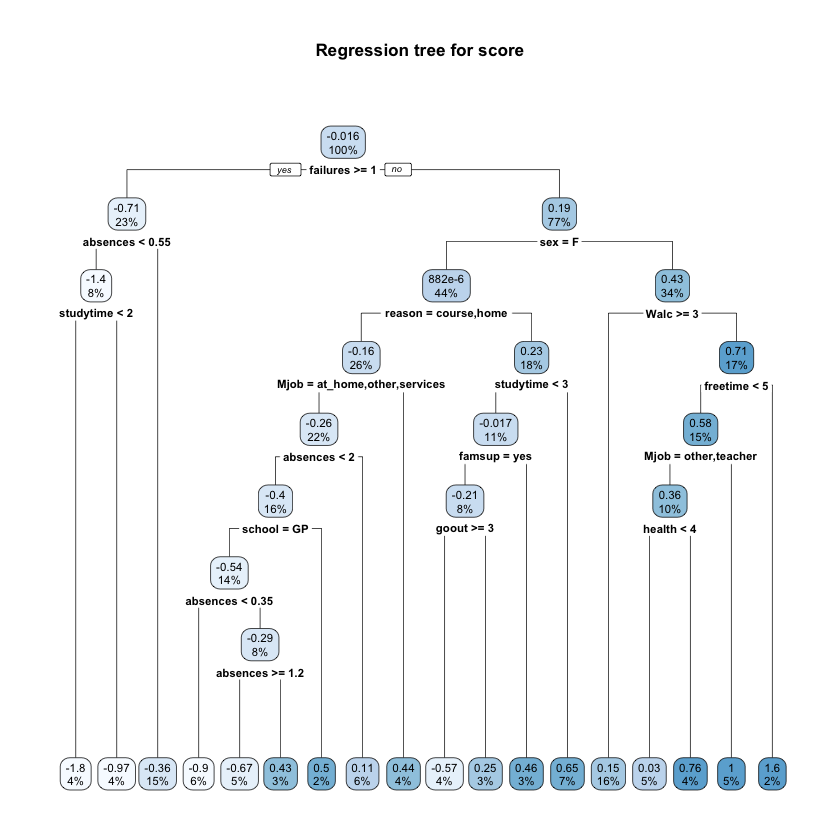

In [7]:
# Single decision tree
tree_model <- rpart(score ~ .,          # Compare score to all other features
                    data = clean_train,
                    method = "anova")   # Use the anova method for regression trees

rpart.plot(tree_model, main = "Regression tree for score")

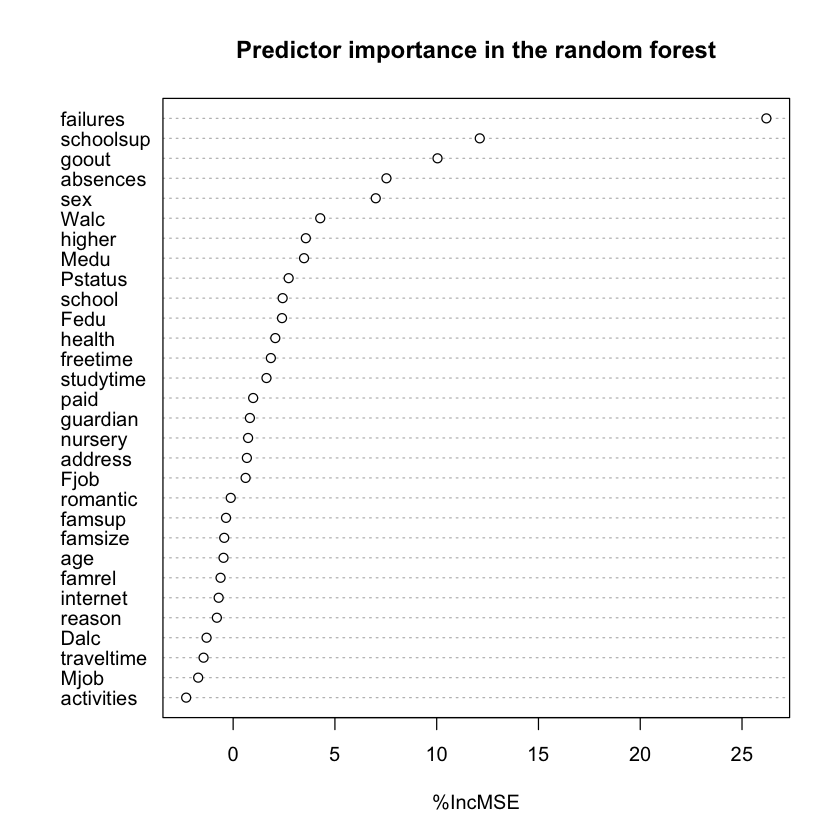

In [8]:
# Random forest
set.seed(45)
rf_model <- randomForest(score ~ .,
                         data = clean_train,
                         importance = TRUE)

# Visualize which variables contribute the most to the predictions
varImpPlot(rf_model, type = 1, main = "Predictor importance in the random forest")

In [9]:
# XGBoost needs a numeric matrix, so factors are one-hot encoded with model.matrix().
# The log transform of absences does not matter for trees, but we use clean_train
# so all models are trained on the same data.
xgb_x <- model.matrix(score ~ . - 1, data = clean_train)
xgb_y <- clean_train$score
xgb_test_x <- model.matrix(~ . - 1, data = clean_test)

# Train and test must have exactly the same columns in the same order
stopifnot(identical(colnames(xgb_x), colnames(xgb_test_x)))

dtrain <- xgb.DMatrix(data = xgb_x, label = xgb_y)

In [10]:
# Tune hyperparameters with 10-fold CV; early stopping picks the number of rounds
xgb_grid <- expand.grid(
  eta              = c(0.01, 0.03),
  max_depth        = c(2, 3, 4),
  min_child_weight = c(1, 5),
  colsample_bytree = c(0.5, 0.8)
)

xgb_tuning <- pmap_dfr(xgb_grid, function(eta, max_depth, min_child_weight, colsample_bytree) {
  set.seed(45)
  cv <- xgb.cv(
    params = list(
      objective        = "reg:squarederror",
      eta              = eta,
      max_depth        = max_depth,
      min_child_weight = min_child_weight,
      subsample        = 0.8,
      colsample_bytree = colsample_bytree
    ),
    data                  = dtrain,
    nrounds               = 3000,
    nfold                 = 10,
    early_stopping_rounds = 50,
    verbose               = 0
  )
  # the location of best_iteration differs between xgboost versions
  best <- if (!is.null(cv$early_stop)) cv$early_stop$best_iteration else cv$best_iteration
  tibble(eta, max_depth, min_child_weight, colsample_bytree,
         nrounds = best,
         cv_mse  = cv$evaluation_log$test_rmse_mean[best]^2)
})

xgb_tuning <- arrange(xgb_tuning, cv_mse)
head(xgb_tuning, 5)


eta,max_depth,min_child_weight,colsample_bytree,nrounds,cv_mse
<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>
0.01,2,5,0.8,354,0.7220431
0.03,2,5,0.8,93,0.7224228
0.03,3,5,0.8,89,0.7224442
0.01,2,1,0.8,361,0.7240192
0.01,3,5,0.8,218,0.7242902


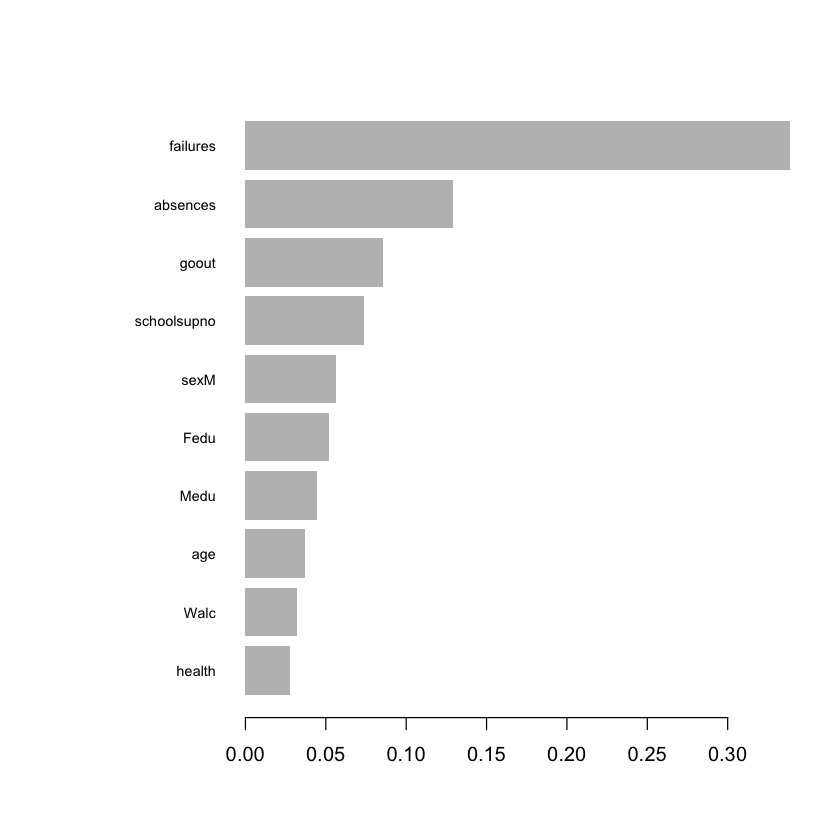

In [11]:
xgb_best <- xgb_tuning[1, ]
xgb_params <- list(
  objective        = "reg:squarederror",
  eta              = xgb_best$eta,
  max_depth        = xgb_best$max_depth,
  min_child_weight = xgb_best$min_child_weight,
  subsample        = 0.8,
  colsample_bytree = xgb_best$colsample_bytree
)

set.seed(45)
xgb_model <- xgb.train(params = xgb_params, data = dtrain,
                       nrounds = xgb_best$nrounds, verbose = 0)

xgb.plot.importance(xgb.importance(model = xgb_model), top_n = 10)


# Model comparison
The test data does not contain the score, so it cannot be used to measure how well a model predicts. Measuring performance on the training data itself is not an option either. We therefore estimate each model's error on unseen data with 10-fold cross-validation on the training data. The 316 students are randomly divided into 10 folds of about 32 students. Each model is trained 10 times, each time on 9 folds, and then predicts the fold it did not see. This gives 10 out-of-sample mean squared errors (MSE) per model, and their average is our estimate of the test MSE. MSE is also the metric used to evaluate models. Every student is used for validation exactly once, so all data are used for both training and evaluation, but never at the same time.

All models are evaluated on exactly the same folds, created once with a fixed seed. This makes the comparison fair, because differences between models cannot be caused by one model getting an easier split than another. Every step that learns from the data is repeated inside each fold using only the training part. For example, the means and standard deviations used to standardise the data for KNN come from the training folds only, so the validation fold stays truly unseen. The trivial baseline described above is evaluated on the same folds as a reference point.

Two models have hyperparameters that we tuned with cross-validation:

* **KNN:** We tuned the number of neighbours, finding k = 15 to be optimal.
* **XGBoost:** We tuned the learning rate, tree depth, minimum leaf size, and fraction of variables per tree; early stopping selected the final number of trees. The best settings were shallow trees (depth 2) with a learning rate of 0.01, a minimum leaf size of 5, 80% of the variables sampled per tree, and 354 trees.

Linear regression, the single regression tree, and the random forest use their default settings. Because the tuned settings were chosen on the same training data, the CV errors of KNN and XGBoost are slightly optimistic. With only 316 students, we preferred this to setting aside a separate validation set, which would leave even less data for training and would itself give a very unstable estimate.


In [12]:
mse <- function(y_true, y_pred) mean((y_true - y_pred)^2)

# Create the folds once; all models use these same folds
k <- 10
set.seed(45)
folds <- sample(rep(1:k, length.out = nrow(clean_train)))

In [13]:
# Baseline: always predict the mean score of the training part
mse_baseline <- rep(0, k)

for (i in 1:k) {
  data_train <- clean_train[folds != i, ]
  data_valid <- clean_train[folds == i, ]

  mse_baseline[i] <- mse(y_true = data_valid$score,
                         y_pred = mean(data_train$score))
}

print("Baseline CV MSE:")
print(mean(mse_baseline))

[1] "Baseline CV MSE:"


[1] 0.9825825


In [14]:
# Cross-validation for linear regression
mse_lm <- rep(0, k)

for (i in 1:k) {
  data_train <- clean_train[folds != i, ]
  data_valid <- clean_train[folds == i, ]

  lm_i <- lm(score ~ ., data = data_train)

  mse_lm[i] <- mse(y_true = data_valid$score,
                   y_pred = predict(lm_i, newdata = data_valid))
}

print("Linear regression CV MSE:")
print(mean(mse_lm))

[1] "Linear regression CV MSE:"


[1] 0.8308551


In [15]:
# Cross-validation for KNN, trying different numbers of neighbours
neighbours <- c(1, 3, 5, 7, 15, 19, 30, 50)
mse_knn_all <- matrix(0, nrow = k, ncol = length(neighbours))

for (i in 1:k) {
  x_cv_train <- knn_x[folds != i, ]
  x_cv_valid <- knn_x[folds == i, ]
  y_cv_train <- knn_y[folds != i]
  y_cv_valid <- knn_y[folds == i]

  # Standardize using the training part of this fold only
  cv_means <- colMeans(x_cv_train)
  cv_sds <- apply(x_cv_train, 2, sd)
  cv_sds[cv_sds == 0] <- 1

  x_cv_train <- scale(x_cv_train, center = cv_means, scale = cv_sds)
  x_cv_valid <- scale(x_cv_valid, center = cv_means, scale = cv_sds)

  for (j in 1:length(neighbours)) {
    knn_i <- knn.reg(train = x_cv_train, test = x_cv_valid,
                     y = y_cv_train, k = neighbours[j])
    mse_knn_all[i, j] <- mse(y_true = y_cv_valid, y_pred = knn_i$pred)
  }
}

# Keep the number of neighbours with the lowest CV MSE
knn_tuning <- data.frame(neighbours = neighbours,
                         cv_mse = colMeans(mse_knn_all))
print(knn_tuning)

knn_best <- neighbours[which.min(colMeans(mse_knn_all))]
mse_knn <- mse_knn_all[, which.min(colMeans(mse_knn_all))]

print("Best number of neighbours:")
print(knn_best)
print("KNN CV MSE:")
print(mean(mse_knn))

  neighbours    cv_mse
1          1 1.5075253
2          3 1.0848357
3          5 1.0132230
4          7 0.9374323
5         15 0.8858514
6         19 0.8892965
7         30 0.9077666
8         50 0.8912186


[1] "Best number of neighbours:"


[1] 15


[1] "KNN CV MSE:"


[1] 0.8858514


In [16]:
# Cross-validation for the regression tree
mse_tree <- rep(0, k)

for (i in 1:k) {
  data_train <- clean_train[folds != i, ]
  data_valid <- clean_train[folds == i, ]

  tree_i <- rpart(score ~ ., data = data_train, method = "anova")

  mse_tree[i] <- mse(y_true = data_valid$score,
                     y_pred = predict(tree_i, newdata = data_valid))
}

print("Regression tree CV MSE:")
print(mean(mse_tree))

[1] "Regression tree CV MSE:"


[1] 0.8870455


In [17]:
# Cross-validation for the random forest
mse_rf <- rep(0, k)

for (i in 1:k) {
  data_train <- clean_train[folds != i, ]
  data_valid <- clean_train[folds == i, ]

  set.seed(45)
  rf_i <- randomForest(score ~ ., data = data_train)

  mse_rf[i] <- mse(y_true = data_valid$score,
                   y_pred = predict(rf_i, newdata = data_valid))
}

print("Random forest CV MSE:")
print(mean(mse_rf))

[1] "Random forest CV MSE:"


[1] 0.7626531


In [18]:
# Cross-validation for XGBoost
mse_xgb <- rep(0, k)

for (i in 1:k) {
  data_train <- clean_train[folds != i, ]
  data_valid <- clean_train[folds == i, ]

  dtrain_i <- xgb.DMatrix(model.matrix(score ~ . - 1, data = data_train),
                          label = data_train$score)

  set.seed(45)
  xgb_i <- xgb.train(params = xgb_params, data = dtrain_i,
                     nrounds = xgb_best$nrounds, verbose = 0)

  mse_xgb[i] <- mse(y_true = data_valid$score,
                    y_pred = predict(xgb_i, model.matrix(score ~ . - 1, data = data_valid)))
}

print("XGBoost CV MSE:")
print(mean(mse_xgb))

[1] "XGBoost CV MSE:"


[1] 0.7446538


# Chosen model

In [19]:
# Collect the cross-validation results of all models
cv_results <- data.frame(
  model = c("Baseline (mean)", "Regression tree", "KNN", "Linear regression",
            "Random forest", "XGBoost"),
  cv_mse = c(mean(mse_baseline), mean(mse_tree), mean(mse_knn),
             mean(mse_lm), mean(mse_rf), mean(mse_xgb))
)
cv_results <- cv_results[order(-cv_results$cv_mse), ]
cv_results

,model,cv_mse
,<chr>,<dbl>
1,Baseline (mean),0.9825825
2,Regression tree,0.8870455
3,KNN,0.8858514
4,Linear regression,0.8308551
5,Random forest,0.7626531
6,XGBoost,0.7446538


We can see that all models beat the baseline, showing that the student characteristics contain predictive information about the score. The two tree ensembles perform best, followed by linear regression, while KNN and the single regression tree improve only modestly on the baseline. For a single decision tree, the limited scope for improvement is understandable, as a single tree often overfits specific training data. Ensemble learning methods can largely address this issue. For KNN, the presence of many one-hot encoded and weakly related variables adds noise to the distances between students, meaning "nearest" neighbours are not necessarily similar in ways that matter for the score.

Taken at face value XGBoost wins. However, the XGBoost result is the more optimistic of the two: its settings were selected by searching 24 parameter combinations on the full training data before the cross-validation was run, so the validation students had already influenced those settings. This is visible in the tuning results themselves: the best combination reached an MSE of 0.722 during tuning, but a higher value when evaluated on our shared folds. The random forest was run with its default settings and had nothing tuned on the data, so its estimate is honest. When two models perform this similarly, the simpler and more reproducible one is preferable. We therefore refitted the random forest on all 316 training students and used it to predict the 79 test students; these predictions are stored in `predictions.rds`. Compared to the baseline, this is a reduction in MSE of about 22%, which is substantial given that the data contain no earlier grades.

In [20]:
# Fit the selected model on the full training data and predict the test data
set.seed(45)
final_model <- randomForest(score ~ ., data = clean_train)
pred_test <- predict(final_model, newdata = clean_test)

# The submission must be a numeric vector of exactly 79 values
stopifnot(length(pred_test) == 79, is.numeric(pred_test))

saveRDS(pred_test, "predictions.rds")